Day 2 – Regression Models & Optimization
Objective: Build Linear Regression from scratch using NumPy without Scikit-learn.

We will continue using the exact same dataset and training/testing split from Day 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print(df.head())
print(df.shape)
print(df.columns.tolist())

Saving crop_yield.csv to crop_yield (1).csv
           Crop  Crop_Year       Season  State     Area  Production  \
0      Arecanut       1997  Whole Year   Assam  73814.0       56708   
1     Arhar/Tur       1997  Kharif       Assam   6637.0        4685   
2   Castor seed       1997  Kharif       Assam    796.0          22   
3      Coconut        1997  Whole Year   Assam  19656.0   126905000   
4  Cotton(lint)       1997  Kharif       Assam   1739.0         794   

   Annual_Rainfall  Fertilizer  Pesticide        Yield  
0           2051.4  7024878.38   22882.34     0.796087  
1           2051.4   631643.29    2057.47     0.710435  
2           2051.4    75755.32     246.76     0.238333  
3           2051.4  1870661.52    6093.36  5238.051739  
4           2051.4   165500.63     539.09     0.420909  
(19689, 10)
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']


Select Features

In [3]:
X = df["Annual_Rainfall"].to_numpy(dtype=float)
y = df["Yield"].to_numpy(dtype=float)

# Remove invalid values
valid = np.isfinite(X) & np.isfinite(y)

X = X[valid]
y = y[valid]

print("Samples:", len(X))

Samples: 19689


In [4]:
np.random.seed(42)

indices = np.random.permutation(len(X))

split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 15751
Testing samples: 3938


Normalize the input
Normalization helps gradient descent converge more smoothly.

In [11]:
X_mean = np.mean(X_train)
X_std = np.std(X_train)

X_train_norm = (X_train - X_mean) / X_std
X_test_norm = (X_test - X_mean) / X_std

# Convert yield into tonnes/hectare
y_train_target = y_train.copy()
y_test_target = y_test.copy()

Our equation:
y = wx+b

In [12]:
w = 0.0
b = 0.0

learning_rate = 0.01
epochs = 1000

n = len(X_train_norm)

loss_history = []

Implement Gradient Descent Manually

In [13]:
for epoch in range(epochs):

    # Forward propagation
    y_pred_train = w * X_train_norm + b

    # Calculate error
    error = y_pred_train - y_train_target

    # Mean Squared Error
    mse = np.mean(error ** 2)

    loss_history.append(mse)

    # Calculate gradients
    dw = (2/n) * np.sum(error * X_train_norm)
    db = (2/n) * np.sum(error)

    # Update parameters
    w -= learning_rate * dw
    b -= learning_rate * db

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, MSE: {mse:.6f}")

print("\nFinal Weight:", w)
print("Final Bias:", b)

Epoch 0, MSE: 771424.192348
Epoch 100, MSE: 765174.340902
Epoch 200, MSE: 765064.418848
Epoch 300, MSE: 765062.485545
Epoch 400, MSE: 765062.451542
Epoch 500, MSE: 765062.450944
Epoch 600, MSE: 765062.450934
Epoch 700, MSE: 765062.450933
Epoch 800, MSE: 765062.450933
Epoch 900, MSE: 765062.450933

Final Weight: 15.484511025069319
Final Bias: 78.24302723696717


Plot the loss curve

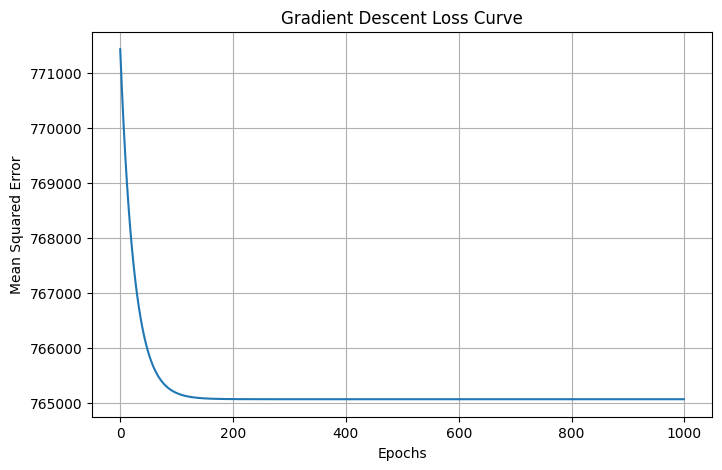

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Loss Curve")

plt.grid()
plt.show()

Test the model

In [15]:
y_pred = w * X_test_norm + b

test_mse = np.mean((y_test - y_pred) ** 2)
test_rmse = np.sqrt(test_mse)
test_mae = np.mean(np.abs(y_test - y_pred))

print("Test MSE:", test_mse)
print("Test RMSE:", test_rmse)
print("Test MAE:", test_mae)

print("\nActual vs Predicted")

for i in range(10):
    print(
        f"Actual: {y_test[i]:.2f} | "
        f"Predicted: {y_pred[i]:.2f}"
    )

Test MSE: 795051.9578237386
Test RMSE: 891.6568610310463
Test MAE: 155.2136370574789

Actual vs Predicted
Actual: 27.90 | Predicted: 89.45
Actual: 0.71 | Predicted: 69.96
Actual: 1.97 | Predicted: 69.98
Actual: 0.62 | Predicted: 83.72
Actual: 1.02 | Predicted: 106.87
Actual: 9.88 | Predicted: 124.24
Actual: 28.89 | Predicted: 71.22
Actual: 0.94 | Predicted: 74.46
Actual: 0.20 | Predicted: 79.35
Actual: 1.87 | Predicted: 72.80


Plot actual vs predicted

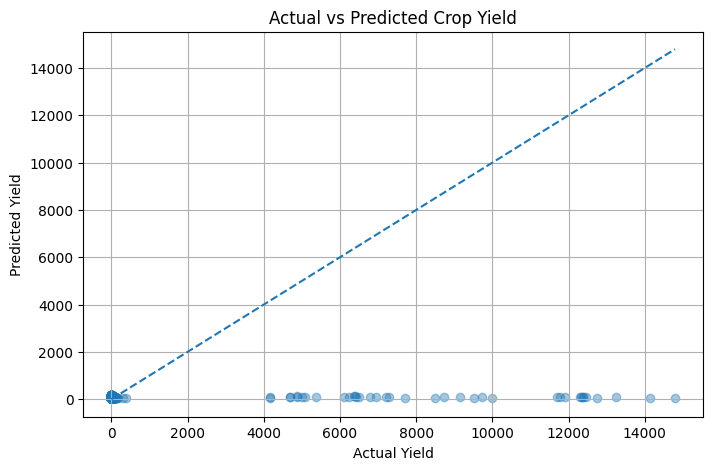

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")

plt.title("Actual vs Predicted Crop Yield")

plt.grid()
plt.show()

In [17]:
baseline_pred = np.full(
    len(y_test), np.mean(y_train)
)

baseline_mse = np.mean(
    (y_test - baseline_pred)**2
)

model_mse = np.mean(
    (y_test - y_pred)**2
)

print("Baseline MSE:", baseline_mse)
print("Model MSE:", model_mse)

improvement = (
    (baseline_mse - model_mse) / baseline_mse
) * 100

print("Improvement:", improvement, "%")

Baseline MSE: 795717.1470426734
Model MSE: 795051.9578237386
Improvement: 0.08359619010436944 %
